# Giới thiệu bài giảng

Trong bài giảng này, chúng ta sẽ tìm hiểu về việc áp dụng phương pháp hồi quy tuyến tính (Linear Regression) để dự đoán mức lương dựa trên số năm kinh nghiệm. Cụ thể, nội dung của bài giảng bao gồm các phần sau:

1. **Chuẩn bị các packages liên quan**: Sử dụng các thư viện phổ biến như NumPy, Pandas và Matplotlib để hỗ trợ việc xử lý dữ liệu và trực quan hóa.
2. **Chuẩn bị Dữ liệu**: Đọc và chuẩn bị dữ liệu từ tệp CSV, sau đó thực hiện trực quan hóa dữ liệu để hiểu rõ hơn về mối quan hệ giữa số năm kinh nghiệm và mức lương.
3. **Xây dựng Mô hình Linear Regression**: 
    - Định nghĩa lớp `LeastSquareSum` để thực hiện hồi quy tuyến tính bằng cách tính toán các hệ số hồi quy thông qua phương pháp bình phương tối thiểu (Ordinary Least Squares - OLS).
    - Sử dụng lớp này để huấn luyện mô hình trên tập dữ liệu đã cho và dự đoán mức lương cho các giá trị kinh nghiệm cụ thể.
4. **Trực quan hóa Kết quả**: Vẽ biểu đồ để so sánh giữa dữ liệu thực tế và đường hồi quy tuyến tính dự đoán. Trực quan hóa này giúp hiểu rõ hơn về khả năng dự đoán của mô hình.
5. **Xử lý Dữ liệu nhiễu**: Trực quan hóa ảnh hưởng của dữ liệu nhiễu đến mô hình hồi quy tuyến tính, qua đó nhận biết được sự sai lệch trong dự đoán khi có sự xuất hiện của dữ liệu không nhất quán.

Bằng việc hoàn thành bài giảng này, học viên sẽ có cái nhìn sâu sắc hơn về phương pháp hồi quy tuyến tính, cách áp dụng nó vào thực tế và cách xử lý dữ liệu để đạt được mô hình dự đoán hiệu quả.

## 1 - Packages

Trong bài giảng này, chúng ta sẽ sử dụng các thư viện sau đây

- `numpy` là thư viện hỗ trợ tính toán mạnh mẽ của **Python**.
- `pandas` là thư viện hỗ trợ việc quản lý và phân tích dữ liệu.
- `matplotlib` là thư viện hỗ trợ việc trực quan hoá, vẽ đồ thị,...

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2 - Thao tác với dữ liệu
Ở phần này, chúng ta sẽ thực hiện các bước sau:

1. Đọc dữ liệu từ file **data.csv**.
2. Xem qua các điểm dữ liệu.
3. Trực quan hoá dữ liệu dưới dạng biểu đồ để có cái nhìn chung về tập dữ liệu.



In [2]:
df = pd.read_csv('data.csv')
df

,Exp,Salary
0,1.0,10
1,2.0,25
2,2.5,20
3,3.5,30
4,3.0,28
5,4.0,50
6,5.0,70
7,1.5,18
8,4.0,40
9,4.5,50


[[1. ]
 [2. ]
 [2.5]
 [3.5]
 [3. ]
 [4. ]
 [5. ]
 [1.5]
 [4. ]
 [4.5]]
[10 25 20 30 28 50 70 18 40 50]
[[2.8]]


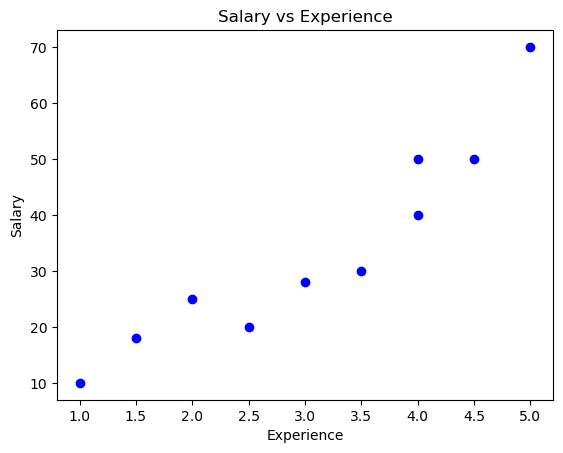

In [3]:
X_data = df['Exp'].to_numpy()[:, np.newaxis]
y_data = df['Salary'].to_numpy()
X_test = np.array([[2.8]])

print(X_data)
print(y_data)
print(X_test)

plt.scatter(X_data, y_data, color='blue')
plt.title ( 'Salary vs Experience')
plt.xlabel( 'Experience')
plt.ylabel( 'Salary')
plt.show()

## 3. Xây dựng lớp `LeastSquareSum`

Lớp `LeastSquareSum` cung cấp một cách đơn giản và hiệu quả để thực hiện hồi quy tuyến tính bằng phương pháp bình phương tối thiểu. Quá trình bao gồm hai việc:
1. Huấn luyện mô hình bằng cách tính toán các hệ số hồi quy từ dữ liệu đầu vào (`fit` method).
2. Sử dụng các hệ số này để dự đoán giá trị của biến phụ thuộc từ dữ liệu mới (`predict` method).

Phương pháp này rất phổ biến trong phân tích thống kê và học máy do tính đơn giản và hiệu quả trong việc dự đoán và phân tích mối quan hệ giữa các biến.
#### Các thành phần của lớp `LeastSquareSum`

1. **`__init__` method**:
   - Khởi tạo các biến `X`, `y`, và `W` là các numpy array. 
   - `X` là ma trận chứa dữ liệu.
   - `y` là vector chứa biến phụ thuộc.
   - `W` là vector chứa các hệ số hồi quy (weights).

2. **`fit` method**:
   - Hàm này thực hiện quá trình huấn luyện mô hình bằng cách ước lượng các hệ số hồi quy từ dữ liệu đầu vào.
   - `X_data` được mở rộng bằng cách thêm cột giá trị 1 (để bao gồm bias term) và được lưu vào `self.X`.
   - `y_data` được chuyển đổi thành numpy array và lưu vào `self.y`.
   - Phương trình hồi quy tuyến tính: $\hat{y} = XW$, trong đó:
     - $X$ là ma trận chứa dữ liệu.
     - $W$ là vector chứa các hệ số hồi quy.
   - Công thức tính toán các hệ số hồi quy: $W = (X^TX)^{-1}X^Ty$:
     - $A = (X^TX)^{-1}$
     - $b = X^Ty$
     - $W = A \cdot b$

3. **`predict` method**:
   - Hàm này sử dụng các hệ số hồi quy đã được tính toán để dự đoán giá trị của biến phụ thuộc từ dữ liệu đầu vào.
   - `X_test` là ma trận chứa các điểm cần dự đoán.
   - Giá trị dự đoán được tính bằng tích của ma trận `X_test` và vector `W`.

In [4]:
class LeastSquareSum:
  def fit(self, X, y):
    X = np.column_stack((np.ones(len(X)), X))
    y = np.array(y)
    A = np.linalg.inv(X.T @ X)
    b = X.T @ y
    self.W = A @ b
    return self
  
  def predict(self, X):
    X = np.column_stack((np.ones(len(X)), X))
    return np.array(X) @ self.W

## 4. Sử dụng lớp LeastSquareSum để huấn luyện và dự đoán

Trong phần này, chúng ta khởi tạo và huấn luyện một mô hình hồi quy tuyến tính bằng cách sử dụng lớp `LeastSquareSum`. Sau khi huấn luyện, mô hình được sử dụng để dự đoán mức lương cho một giá trị kinh nghiệm cụ thể. Các hệ số của mô hình và kết quả dự đoán được hiển thị để kiểm tra.

Các bước thực hiện bao gồm

1. **Khởi tạo Mô hình**:
   - Tạo một đối tượng của lớp `LeastSquareSum` bằng cách gọi `LSS = LeastSquareSum()`.

2. **Huấn luyện Mô hình**:
   - Sử dụng phương thức `fit` của đối tượng `LSS` để huấn luyện mô hình trên tập dữ liệu `X_data` và `y_data`.
   - Các hệ số hồi quy được tính toán và lưu trữ trong `W_pred`.

3. **Dự đoán Giá trị**:
   - Sử dụng phương thức `predict` của đối tượng `LSS` để dự đoán mức lương (`Salary`) dựa trên giá trị kinh nghiệm (`exp`) từ `X_test`.

4. **Hiển thị Kết quả**:
   - In các hệ số hồi quy của mô hình (`W_pred`).
   - In giá trị dự đoán của mức lương cho một giá trị kinh nghiệm cụ thể từ `X_test`.

In [5]:
LSS = LeastSquareSum()
W_pred = LSS.fit(X_data, y_data).W
print('Model weights: ', W_pred)
print(f'With exp = {X_test[0]}, predict salary = {LSS.predict(X_test)[0]}')

Model weights:  [-5.65408805 12.82389937]
With exp = [2.8], predict salary = 30.252830188679205


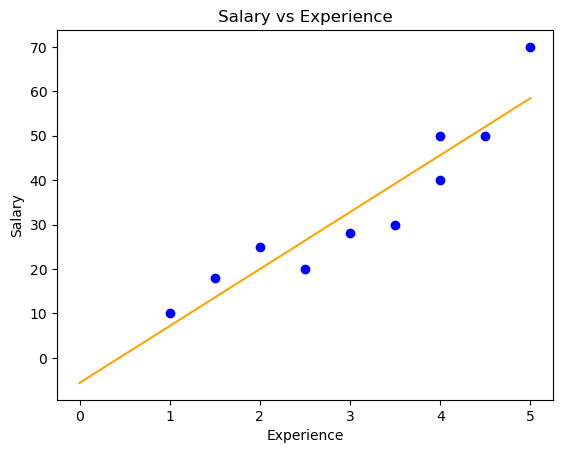

In [6]:
plt.scatter(X_data, y_data, color='blue')

X_interval = np.linspace(0, 5, 100).reshape(-1, 1)
y_interval_pred = LSS.predict(X_interval)

plt.plot(X_interval, y_interval_pred, color='orange')
plt.title ( 'Salary vs Experience')    
plt.xlabel( 'Experience')    
plt.ylabel( 'Salary')    
plt.show()

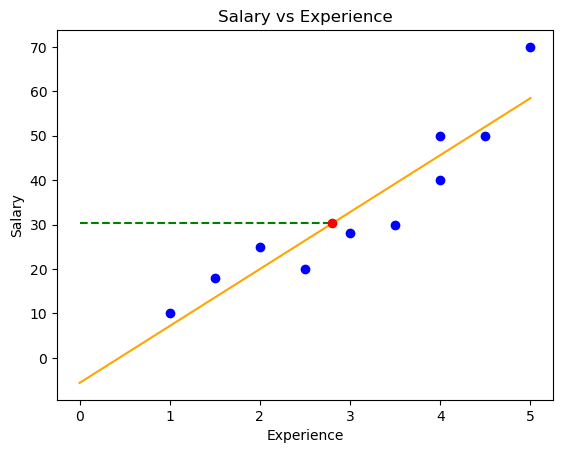

In [7]:
plt.scatter(X_data, y_data, color='blue')   

X_interval = np.linspace(0, 5, 100).reshape(-1, 1)
y_interval_pred = LSS.predict(X_interval)
plt.plot(X_interval, y_interval_pred, color='orange')  

y_pred = LSS.predict(X_test)
plt.scatter(X_test, y_pred, color='red', zorder=10)
for i in range(len(X_test)):
    plt.plot(np.linspace(0, X_test[i], 100), [y_pred[i] for _ in range(100)], 'g--')

plt.title(  'Salary vs Experience')    
plt.xlabel( 'Experience')    
plt.ylabel( 'Salary')    
plt.show()

## 5. Regularization

### Linear regression with noise

Trong phần này, chúng ta sẽ thêm một số điểm dữ liệu nhiễu, gọi là noise vào tập dữ liệu ban đầu và quan sát sự thay đổi của các tham số cũng như đường thẳng hồi quy so với bộ dữ liệu ban đầu.


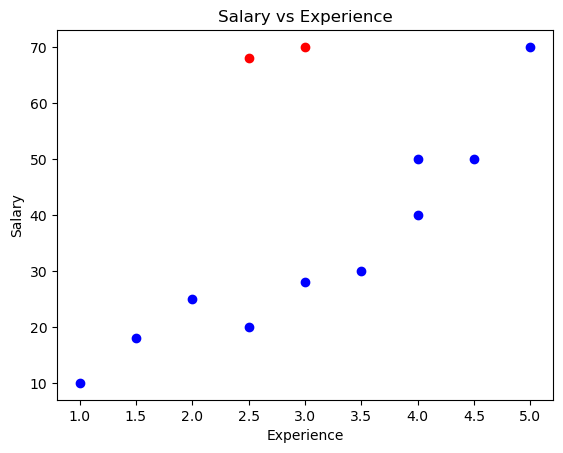

In [8]:
X_noise = np.array([[3], [2.5]])
y_noise = np.array([70, 68])

plt.scatter(X_data, y_data, color='blue')     
plt.scatter(X_noise, y_noise, color='red')     

plt.title(  'Salary vs Experience')    
plt.xlabel( 'Experience')    
plt.ylabel( 'Salary')    
plt.show()

In [9]:
X_with_noise = np.concatenate((X_data, X_noise))
y_with_noise = np.concatenate((y_data, y_noise))

lr = LeastSquareSum().fit(X_with_noise, y_with_noise)
print('Weights:', lr.W)

Weights: [ 5.42362003 11.34017972]


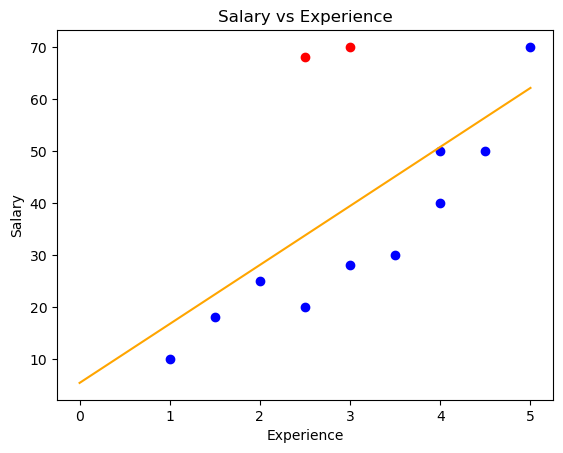

In [10]:
plt.scatter(X_data, y_data, color='blue' )   
plt.scatter(X_noise, y_noise, color='red' )     

X_interval = np.linspace(0, 5, 100)
plt.plot(X_interval, lr.predict(X_interval), color='orange')  

plt.title(  'Salary vs Experience')    
plt.xlabel( 'Experience')    
plt.ylabel( 'Salary')    
plt.show()

### L2 Regularization trong Linear Regression

Để hạn chế vấn đề overfitting của Linear Regression, người ta có thể thêm vào một trọng số phạt. Nếu trọng số phạt dựa trên phương pháp L2 Regularization, mô hình Linear Regression bây giờ còn có tên gọi khác là Ridge Regression. Có thể nói, Ridge Regression là một phương pháp cải tiến của Linear Regression nhằm giải quyết vấn đề overfitting bằng cách thêm một thuật toán phạt vào hàm mất mát. Công thức của Ridge Regression như sau:`

$$ W = (X^T X + \lambda I)^{-1} X^T y $$

Trong đó:
- $ \lambda $ là tham số điều chỉnh (regularization parameter), kiểm soát mức độ phạt. Giá trị càng lớn, mức độ phạt càng cao.
- $ I $ là ma trận đơn vị, đảm bảo rằng phép toán nghịch đảo có thể thực hiện được ngay cả khi $ X^T X $ không khả nghịch.

Ridge Regression không chỉ tối thiểu hóa sai số dự đoán mà còn hạn chế độ lớn của các trọng số, từ đó giúp mô hình trở nên ổn định hơn trước dữ liệu nhiễu.

**Giải thích Code**
1. **Lớp `RidgeRegression`**:
   - `__init__`: Khởi tạo với tham số điều chỉnh $ \lambda $. Biến `self.W` được khởi tạo là `np.array`.
   - `fit`: 
     - Thêm cột các giá trị 1 vào dữ liệu đầu vào `X` để xử lý hệ số chặn (intercept).
     - Tạo ma trận đơn vị `I` có cùng số cột với `X`. Phần tử đầu tiên của `I` được đặt là 0 để không phạt hệ số chặn.
     - Tính toán trọng số `W` sử dụng công thức Ridge Regression: 
       $ W = (X^T X + \lambda I)^{-1} X^T y $
   - `predict`: 
     - Thêm cột các giá trị 1 vào dữ liệu kiểm tra `X_test`.
     - Tính toán giá trị dự đoán bằng cách nhân `X_test` với trọng số `W`.

2. **Sử dụng Lớp**:
   - Khởi tạo đối tượng `RidgeRegression` với tham số $ \lambda = 5.0 $.
   - Huấn luyện mô hình với dữ liệu có nhiễu `X_with_noise` và `y_with_noise`.
   - Dự đoán giá trị mục tiêu cho `X_test`.

In [11]:
class RidgeRegression:
    def __init__(self, lamb) -> None:
        self.lamb = lamb

    def fit(self, X, y):
        X = np.column_stack((np.ones(len(X)), X))
        y = np.array(y)
        I = np.identity(X.shape[1])
        I[0, 0] = 0
        A = np.linalg.inv(X.T @ X + self.lamb * I)
        b = X.T @ y
        self.W = A @ b
        return self
  
    def predict(self, X_test):
        X_test = np.column_stack((np.ones(len(X_test)), X_test))
        return np.array(X_test) @ self.W

In [12]:
ridge = RidgeRegression(lamb=5.0)
ridge.fit(X_with_noise, y_with_noise)
print('Weights: ', ridge.W)
print('With exp =', X_test, 'predict Salary:', ridge.predict(X_test))

Weights:  [13.54759568  8.66928361]
With exp = [[2.8]] predict Salary: [37.82158979]


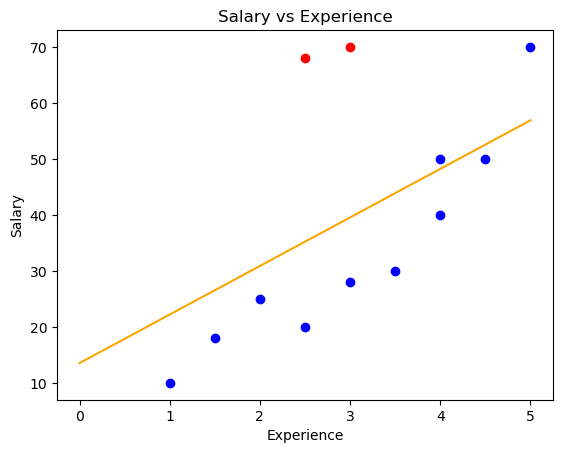

In [13]:
plt.scatter(X_data, y_data, color = 'blue' )    
plt.scatter(X_noise, y_noise, color = 'red' )   
  
plt.title(  'Salary vs Experience' )    
plt.xlabel( 'Experience' )    
plt.ylabel( 'Salary' ) 
X_interval = np.linspace(0, 5, 100)
y_interval = ridge.predict(X_interval)
plt.plot(X_interval, y_interval, color='orange')

plt.show()

# Sử dụng thư viện `sklearn` để triển khai Linear Regression, Ridge Regression và Lasso Regression

Trong phần này, chúng ta sẽ tìm hiểu cách sử dụng thư viện `sklearn` để triển khai các mô hình Linear Regression, Ridge Regression và Lasso Regression. Thư viện `sklearn` cung cấp các công cụ mạnh mẽ và dễ sử dụng để thực hiện các thuật toán học máy, giúp đơn giản hóa quá trình xây dựng và đánh giá các mô hình. Chúng ta sẽ áp dụng các mô hình này trên dữ liệu mẫu và so sánh kết quả dự đoán.

Thông qua các ví dụ bên dưới, chúng ta sẽ thấy được cách triển khai và so sánh các mô hình hồi quy tuyến tính, Ridge và Lasso sử dụng thư viện `sklearn`. Mỗi mô hình có những ưu điểm riêng, phù hợp với từng loại dữ liệu và mục tiêu phân tích khác nhau.

### Linear Regression trên dữ liệu ban đầu

In [14]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_data, y_data)
W_pred = np.array([lr.intercept_, lr.coef_[0]])

print('Model weights: ', W_pred)
print('With exp =', X_test, 'predict Salary:', lr.predict(X_test))

Model weights:  [-5.65408805 12.82389937]
With exp = [[2.8]] predict Salary: [30.25283019]


### Linear Regression trên dữ liệu nhiễu

In [15]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_with_noise, y_with_noise)
W_pred = np.array([lr.intercept_, lr.coef_[0]])

print('Model weights: ', W_pred)
print('With exp =', X_test, 'predict Salary:', lr.predict(X_test))

Model weights:  [ 5.42362003 11.34017972]
With exp = [[2.8]] predict Salary: [37.17612323]


### Ridge Regression trên dữ liệu nhiễu

In [16]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=5.0)
ridge.fit(X_with_noise, y_with_noise)
W_pred = np.array([ridge.intercept_, ridge.coef_[0]])

print('Model weights: ', W_pred)
print('With exp =', X_test, 'predict Salary:', ridge.predict(X_test))

Model weights:  [13.54759568  8.66928361]
With exp = [[2.8]] predict Salary: [37.82158979]


### Lasso Regression trên dữ liệu nhiễu

In [17]:
from sklearn.linear_model import  Lasso

lasso = Lasso(alpha=5.0)
lasso.fit(X_with_noise, y_with_noise)
W_pred = np.array([lasso.intercept_, lasso.coef_[0]])

print('Model weights: ', W_pred)
print('With exp =', X_test, 'predict Salary:', lasso.predict(X_test))

Model weights:  [16.66880616  7.64313222]
With exp = [[2.8]] predict Salary: [38.06957638]
